# Cómo se hacen las noticias de la Unison: antes, durante y después de la pandemia (2015–2026)

En los notebooks anteriores estudiamos **de qué** hablan las noticias. Aquí estudiamos **cómo están hechas**:
cuántas se publican y quién las escribe, qué tan largas son, a quién citan, con qué verbos, y hasta qué palabras pequeñas
(*de, la, que, los*) usan más. A este análisis del estilo se le llama **estilometría**.

**La pregunta:** ¿cambió la forma de hacer las noticias con la pandemia? ¿Y qué cambió después?

Usamos cuatro etapas, que el propio análisis justifica (sección 6):

| Etapa | Años |
|---|---|
| Antes | 2015–2019 |
| Pandemia | 2020–2021 |
| Después | 2022–2024 |
| Nueva etapa | 2025–2026 |

En las gráficas, la **pandemia** va sombreada en rojo y la **nueva etapa** en morado.

## 1. Librerías

In [1]:
import json
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords

## 2. Carga de datos

Además de lo de siempre, preparamos dos columnas que usaremos varias veces:

- **firma:** quién escribió la nota. Desde 2018 es el nombre del autor; antes, las iniciales al final del texto (*(JAR)*, *(BE)*;
  ver notebook 01). Unificamos las variantes de un mismo nombre (*Haydee* / *Haydeé Gaxiola*).
- **etapa:** antes, pandemia, después o nueva etapa.

In [2]:
registros = []
with open("data/raw/noticias_unison.jsonl", encoding="utf-8") as archivo:
    for linea in archivo:
        try:
            registros.append(json.loads(linea))
        except json.JSONDecodeError:
            pass  # línea incompleta mientras el scraper escribe

noticias = pd.DataFrame(registros)
noticias = noticias[noticias["estado"] == "ok"].drop_duplicates(subset="id", keep="last")
noticias = noticias.sort_values("id").reset_index(drop=True)
noticias["fecha"] = pd.to_datetime(noticias["fecha"])
noticias["anio"] = noticias["fecha"].dt.year
noticias["n_palabras"] = noticias["n_palabras"].astype(int)
noticias["n_parrafos"] = noticias["n_parrafos"].astype(int)
noticias = noticias[noticias["n_palabras"] >= 30].reset_index(drop=True)

anios = sorted(noticias["anio"].unique())
print("Noticias:", len(noticias))

Noticias: 19813


In [3]:
# Variantes del mismo nombre que encontramos revisando los autores más frecuentes
VARIANTES_AUTOR = {
    "Beatriz Angélica Espinoza": "Beatriz Espinoza", "Beatriz Angélica Espinoza Sotelo": "Beatriz Espinoza",
    "Haydeé Gaxiola": "Haydee Gaxiola", "Luz Haydee Gaxiola Cabrera": "Haydee Gaxiola",
    "Luz Haydeé Gaxiola Cabrera": "Haydee Gaxiola",
    "Paula Trespalacios": "Paula Trespalacios Argain", "Paula Trespalcios Argain": "Paula Trespalacios Argain",
    "Lin Mendívil Alvarado": "Lin Mendivil Alvarado",
    "Denisse López Martínez": "Denice López Martínez", "Denise López Martínez": "Denice López Martínez",
    "Elias Quijada": "Elías Quijada", "Elías Quijada López": "Elías Quijada",
    "Jesús Albero Rubio": "Jesús Alberto Rubio",
}
noticias["autor"] = noticias["autor"].str.replace(r"^Por:? ", "", regex=True).str.strip().replace(VARIANTES_AUTOR)

iniciales = noticias["texto"].str.strip().str.extract(r"\(([A-ZÁÉÍÓÚÑ]{2,6})\)\.?$")[0]   # "(JAR)" al final
noticias["firma"] = noticias["autor"].fillna(iniciales)


def etapa(anio):
    if anio <= 2019:
        return "Antes (2015–2019)"
    if anio <= 2021:
        return "Pandemia (2020–2021)"
    if anio <= 2024:
        return "Después (2022–2024)"
    return "Nueva etapa (2025–2026)"


noticias["etapa"] = noticias["anio"].apply(etapa)
etapas = list(noticias["etapa"].drop_duplicates())


def marcar_etapas(eje):
    """Sombrea la pandemia (rojo) y la nueva etapa (morado) en una gráfica por año."""
    eje.axvspan(2019.5, 2021.5, color="tab:red", alpha=0.08)
    eje.axvspan(2024.5, 2026.5, color="tab:purple", alpha=0.08)


noticias["etapa"].value_counts()[etapas]

etapa
Antes (2015–2019)          10529
Pandemia (2020–2021)        2302
Después (2022–2024)         4720
Nueva etapa (2025–2026)     2262
Name: count, dtype: int64

## 3. La producción: cuántas, cuándo y quién

### 3.1 ¿Cuántas noticias?

2026 va incompleto, así que además del total comparamos todos los años **hasta el mismo día del año** que la última nota.

In [4]:
ultima_fecha = noticias["fecha"].max()
hasta_mismo_dia = noticias[noticias["fecha"].dt.day_of_year <= ultima_fecha.day_of_year]

produccion = pd.DataFrame({
    "noticias": noticias["anio"].value_counts().sort_index(),
    f"hasta el {ultima_fecha.strftime('%d/%m')}": hasta_mismo_dia["anio"].value_counts().sort_index(),
})
produccion

,noticias,hasta el 29/10
anio,,
2015,2377,1902
2016,2337,1898
2017,2052,1658
2018,2058,1697
2019,1705,1333
2020,946,697
2021,1356,1058
2022,1613,1313
2023,1650,1350


### 3.2 ¿Cuándo se publican?

- **Días con noticias:** cuántos días del año tuvieron al menos una nota (en 2026, sobre los días transcurridos).
- **Fin de semana:** qué parte de las notas sale en sábado o domingo.

In [5]:
dias_transcurridos = pd.Series({anio: 366 if anio % 4 == 0 else 365 for anio in anios})
dias_transcurridos[ultima_fecha.year] = ultima_fecha.day_of_year

cuando = pd.DataFrame({
    "% de días con noticias": noticias.groupby("anio")["fecha"].nunique() / dias_transcurridos * 100,
    "noticias por día publicado": noticias.groupby("anio").size() / noticias.groupby("anio")["fecha"].nunique(),
    "% en fin de semana": (noticias["fecha"].dt.day_of_week >= 5).groupby(noticias["anio"]).mean() * 100,
})
cuando.round(1)

,% de días con noticias,noticias por día publicado,% en fin de semana
anio,,,
2015,77.8,8.4,2.0
2016,85.5,7.5,5.4
2017,84.9,6.6,5.1
2018,82.5,6.8,5.4
2019,76.7,6.1,3.5
2020,67.2,3.8,7.1
2021,80.5,4.6,7.5
2022,76.2,5.8,2.6
2023,80.3,5.6,4.5


### 3.3 ¿Quién las escribe?

Contamos las **firmas** con al menos 20 notas en el año (el equipo de reporteros) y qué parte de las notas firmadas escriben
las tres firmas principales.

In [6]:
equipo = {}
for anio, notas_del_anio in noticias.groupby("anio"):
    por_firma = notas_del_anio["firma"].value_counts()
    equipo[anio] = {
        "% de notas firmadas": notas_del_anio["firma"].notna().mean() * 100,
        "firmas con 20+ notas": (por_firma >= 20).sum(),
        "% de las 3 principales": por_firma.head(3).sum() / por_firma.sum() * 100,
    }

pd.DataFrame(equipo).T.round(1)

,% de notas firmadas,firmas con 20+ notas,% de las 3 principales
2015,84.2,9.0,67.9
2016,87.7,9.0,60.7
2017,80.8,8.0,72.7
2018,85.7,12.0,37.7
2019,92.8,8.0,63.7
2020,94.1,7.0,66.2
2021,94.2,9.0,59.3
2022,95.4,8.0,68.7
2023,96.7,7.0,63.5
2024,97.1,6.0,76.9


El equipo año por año: qué parte de las notas firmadas escribe cada firma (las que tienen al menos 300 notas en total).

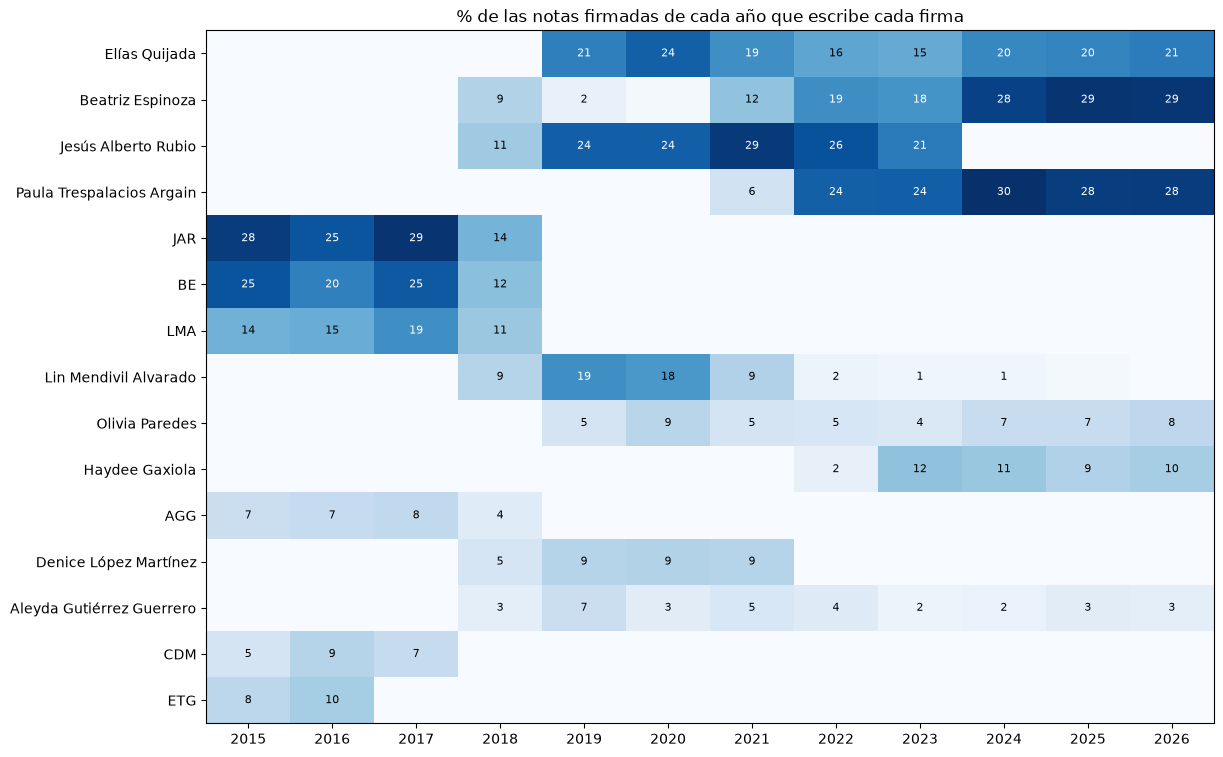

In [7]:
firmas_principales = noticias["firma"].value_counts()
firmas_principales = firmas_principales[firmas_principales >= 300].index

reparto = pd.crosstab(noticias["firma"], noticias["anio"], normalize="columns") * 100
reparto = reparto.loc[firmas_principales]

plt.figure(figsize=(13, 0.5 * len(reparto) + 1.5))
plt.imshow(reparto, cmap="Blues", aspect="auto")
plt.yticks(range(len(reparto)), reparto.index)
plt.xticks(range(len(anios)), anios)
for i in range(len(reparto)):
    for j in range(len(anios)):
        valor = reparto.iloc[i, j]
        if valor >= 1:
            plt.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=8, color="white" if valor > 18 else "black")
plt.title("% de las notas firmadas de cada año que escribe cada firma")
plt.show()

## 4. La forma: largo, párrafos, oraciones y legibilidad

Para cada noticia calculamos:

- **Palabras, párrafos y palabras por párrafo.**
- **Oraciones y palabras por oración.** Contamos oraciones por los signos `. ! ?`; las abreviaturas (*Dr.*, *Lic.*) cuentan de más,
  pero lo hacen igual en todos los años.
- **Legibilidad (INFLESZ):** el índice de Szigriszt-Pazos, la adaptación al español de la fórmula de Flesch. Combina palabras por
  oración y sílabas por palabra: entre más alto, más fácil de leer (menos de 40 es "muy difícil"; 40–55, "algo difícil";
  55–65, "normal"; más de 65, "fácil").
  Contamos las sílabas de forma aproximada: cada grupo de vocales seguidas es una sílaba.

In [8]:
def contar_silabas(palabra):
    """Aproximación: cada grupo de vocales seguidas cuenta como una sílaba."""
    return max(1, len(re.findall(r"[aeiouáéíóúü]+", palabra)))


def inflesz(texto, n_oraciones):
    """Índice de legibilidad de Szigriszt-Pazos: 206.835 - 62.3 * sílabas/palabras - palabras/oraciones."""
    palabras = re.findall(r"[a-záéíóúüñ]+", texto.lower())
    silabas = sum(contar_silabas(palabra) for palabra in palabras)
    return 206.835 - 62.3 * silabas / len(palabras) - len(palabras) / n_oraciones


noticias["n_oraciones"] = noticias["texto"].str.count(r"[.!?]+(\s|$)").clip(lower=1)
noticias["palabras_por_oracion"] = noticias["n_palabras"] / noticias["n_oraciones"]
noticias["palabras_por_parrafo"] = noticias["n_palabras"] / noticias["n_parrafos"]
noticias["legibilidad"] = [inflesz(texto, n) for texto, n in zip(noticias["texto"], noticias["n_oraciones"])]

FORMA = {
    "n_palabras": "Palabras por noticia",
    "n_parrafos": "Párrafos por noticia",
    "palabras_por_parrafo": "Palabras por párrafo",
    "n_oraciones": "Oraciones por noticia",
    "palabras_por_oracion": "Palabras por oración",
    "legibilidad": "Legibilidad (INFLESZ)",
}
forma = noticias.groupby("anio")[list(FORMA)].median().rename(columns=FORMA)   # mediana: no la mueven las notas extremas
forma.round(1)

,Palabras por noticia,Párrafos por noticia,Palabras por párrafo,Oraciones por noticia,Palabras por oración,Legibilidad (INFLESZ)
anio,,,,,,
2015,371.0,8.0,46.6,9.0,41.9,28.3
2016,382.0,8.0,46.0,9.0,41.9,27.8
2017,375.0,8.0,46.2,9.0,42.3,28.5
2018,382.5,8.0,45.0,9.0,41.4,28.5
2019,435.0,9.0,47.8,10.0,44.3,24.2
2020,518.0,10.0,50.1,12.0,45.0,23.6
2021,587.0,12.0,47.4,13.0,44.0,25.0
2022,537.0,13.0,42.6,13.0,42.9,28.4
2023,478.0,12.0,39.9,11.0,42.4,29.5


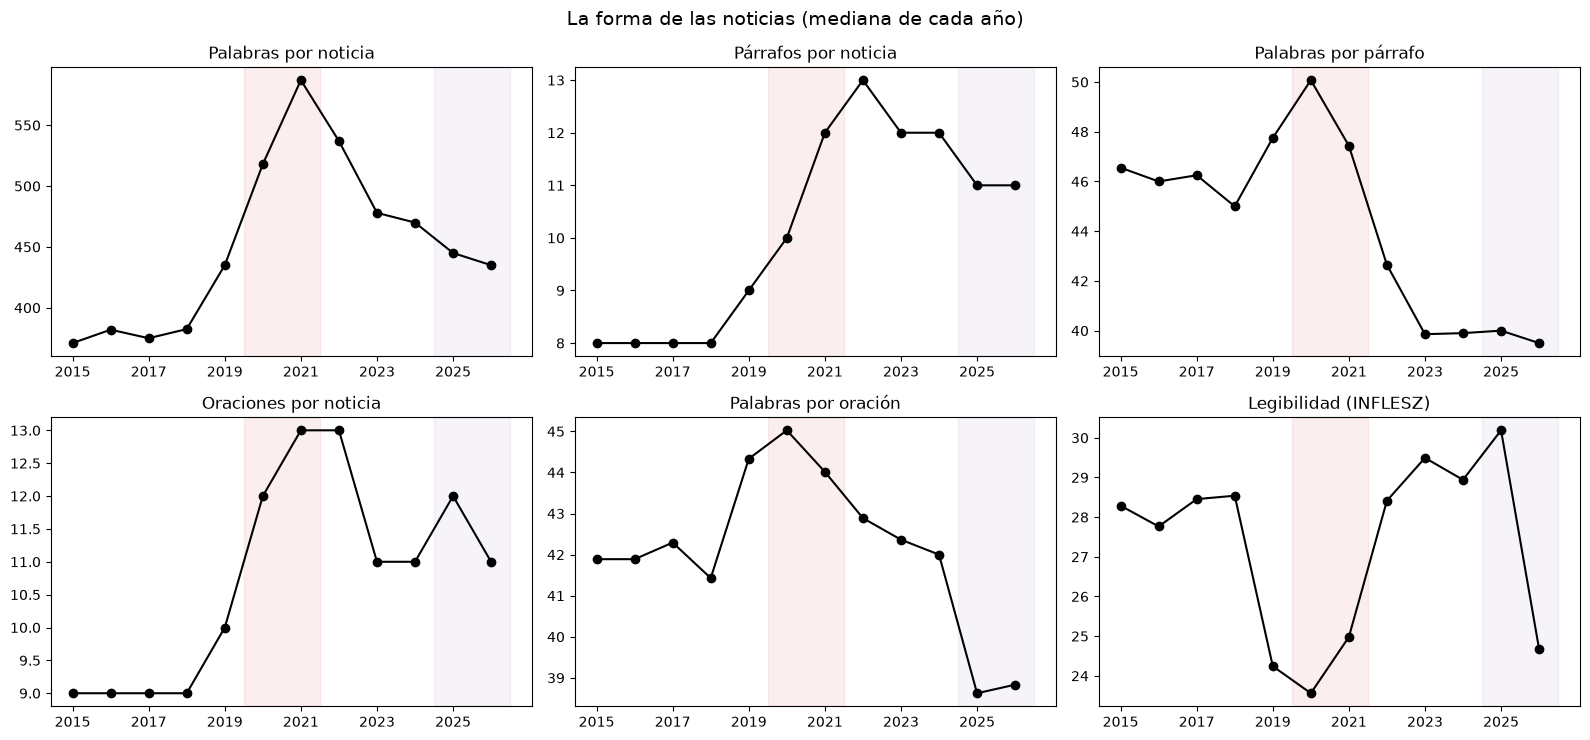

In [9]:
def graficar_por_anio(tabla, titulo_general):
    """Una gráfica pequeña por columna de la tabla, con las etapas sombreadas."""
    fig, ejes = plt.subplots(2, 3, figsize=(16, 7.5))
    for columna, eje in zip(tabla.columns, ejes.flatten()):
        eje.plot(tabla.index, tabla[columna], marker="o", color="black")
        marcar_etapas(eje)
        eje.set_title(columna)
        eje.set_xticks(anios[::2])
    fig.suptitle(titulo_general, fontsize=14)
    plt.tight_layout()
    plt.show()


graficar_por_anio(forma, "La forma de las noticias (mediana de cada año)")

## 5. Las voces: citas, titulares y verbos

### 5.1 Citas textuales

¿Qué parte del texto son **palabras de otros**, entre comillas? Contamos las palabras dentro de comillas (“ ” o " ").

In [10]:
citas = noticias["texto"].str.findall(r"[“\"]([^”\"]{3,})[”\"]")      # cada cita, sin las comillas
noticias["tiene_cita"] = citas.str.len() > 0
noticias["porcentaje_en_citas"] = citas.apply(lambda lista: sum(len(cita.split()) for cita in lista)) / noticias["n_palabras"] * 100

voces = pd.DataFrame({
    "% de notas con alguna cita": noticias.groupby("anio")["tiene_cita"].mean() * 100,
    "% del texto entre comillas": noticias.groupby("anio")["porcentaje_en_citas"].mean(),
})
voces.round(1)

,% de notas con alguna cita,% del texto entre comillas
anio,,
2015,86.7,14.7
2016,80.1,14.3
2017,70.4,13.2
2018,69.8,13.2
2019,76.9,15.5
2020,79.2,17.4
2021,86.4,20.6
2022,92.6,24.6
2023,87.9,22.3


### 5.2 Titulares con cita

Un estilo común de titular termina con dos puntos y quien habla:
*"Unison, pionera en donación altruista de sangre: **rectora**"*. Leemos lo que va después de los dos puntos para saber **a quién
se cita en el titular**: la rectora o el rector, académicos y especialistas, estudiantes, funcionarios, o una persona por su nombre.

In [11]:
def quien_habla(titulo):
    """Quién habla en un titular del tipo 'frase: quien la dijo'."""
    if not re.search(r":\s*\S", titulo):
        return "sin cita en el titular"
    despues = titulo.split(":")[-1].strip()
    minusculas = despues.lower()
    if re.search(r"rector|velázquez contreras|plancarte|camarena|grijalva", minusculas):
        return "rector(a)"
    if re.search(r"académic|especialista|investigador|expert|economista|docente|profesor|catedrátic|científic", minusculas):
        return "académicos y especialistas"
    if re.search(r"estudiante|alumn|egresad", minusculas):
        return "estudiantes"
    if re.search(r"director|secretari|coordinador|jefe|titular|vicerrector|funcionari|president|gobernador", minusculas):
        return "funcionarios"
    if re.fullmatch(r"[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+( (de |del |la )?[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+){1,4}", despues):
        return "una persona por su nombre"
    return "otro (no es una cita)"


noticias["quien_habla"] = noticias["titulo"].apply(quien_habla)
titulares = pd.crosstab(noticias["anio"], noticias["quien_habla"], normalize="index") * 100
titulares.round(1)

quien_habla,académicos y especialistas,estudiantes,funcionarios,otro (no es una cita),rector(a),sin cita en el titular,una persona por su nombre
anio,,,,,,,
2015,2.8,0.2,0.0,2.1,0.7,91.4,2.9
2016,1.0,0.1,0.0,1.8,0.7,89.4,7.0
2017,1.3,0.0,0.0,2.8,1.4,88.0,6.5
2018,1.5,0.4,0.0,3.5,0.6,89.4,4.6
2019,0.9,0.8,0.1,5.7,0.8,84.4,7.3
2020,1.3,0.3,0.0,2.3,0.6,86.9,8.6
2021,1.7,0.3,0.0,3.7,1.3,82.4,10.6
2022,4.3,0.6,0.1,4.6,0.7,83.9,6.0
2023,3.5,0.8,0.1,2.8,0.7,87.5,4.8


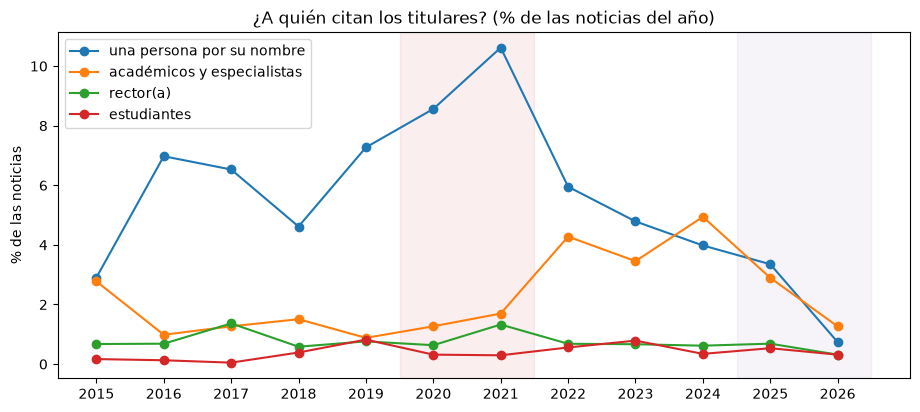

In [12]:
plt.figure(figsize=(11, 4.5))
for categoria in ["una persona por su nombre", "académicos y especialistas", "rector(a)", "estudiantes"]:
    plt.plot(titulares.index, titulares[categoria], marker="o", label=categoria)
marcar_etapas(plt.gca())
plt.title("¿A quién citan los titulares? (% de las noticias del año)")
plt.ylabel("% de las noticias")
plt.xticks(anios)
plt.legend()
plt.show()

### 5.3 Los verbos con que se cita

*"... **dijo** la rectora"*, *"... **destacó** el investigador"*. El verbo que acompaña una cita no es neutral:
*dijo* solo informa; *destacó*, *compartió* o *subrayó* ya valoran lo dicho. Contamos cada verbo por cada 10,000 palabras en cada etapa.

In [13]:
VERBOS_DE_CITA = ["dijo", "señaló", "indicó", "destacó", "añadió", "expresó", "comentó", "mencionó", "informó", "explicó",
                  "agregó", "resaltó", "apuntó", "afirmó", "precisó", "subrayó", "consideró", "advirtió", "sostuvo",
                  "puntualizó", "reconoció", "aseguró", "compartió", "detalló", "enfatizó"]

palabras_por_noticia = noticias["texto"].str.lower().str.findall(r"[a-záéíóúüñ]+")

verbos = {}
for nombre_etapa in etapas:
    palabras_de_la_etapa = palabras_por_noticia[noticias["etapa"] == nombre_etapa]
    conteo = Counter()
    total = 0
    for palabras in palabras_de_la_etapa:
        conteo.update(palabra for palabra in palabras if palabra in VERBOS_DE_CITA)
        total += len(palabras)
    verbos[nombre_etapa] = {verbo: conteo[verbo] / total * 10000 for verbo in VERBOS_DE_CITA}

verbos = pd.DataFrame(verbos)
verbos.round(1)

,Antes (2015–2019),Pandemia (2020–2021),Después (2022–2024),Nueva etapa (2025–2026)
dijo,16.8,15.0,16.4,8.3
señaló,8.7,8.4,8.1,9.1
indicó,8.3,9.4,7.8,5.1
destacó,7.6,6.7,6.5,11.6
añadió,7.6,5.2,5.9,5.8
expresó,6.7,7.0,8.0,8.6
comentó,6.3,5.4,7.2,4.7
mencionó,4.6,4.3,3.0,2.7
informó,4.5,3.2,3.7,3.4
explicó,4.4,5.8,6.8,9.5


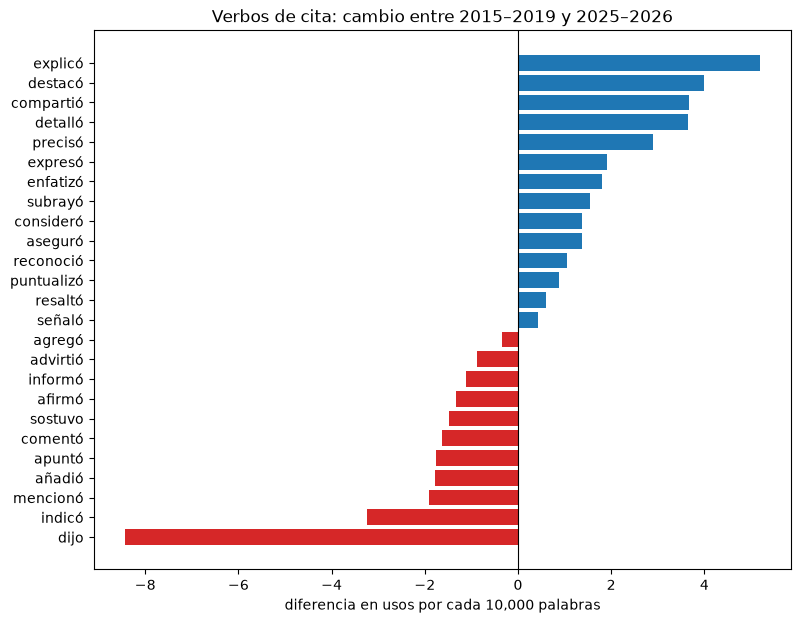

In [14]:
cambio_verbos = (verbos["Nueva etapa (2025–2026)"] - verbos["Antes (2015–2019)"]).sort_values()
colores = ["tab:red" if valor < 0 else "tab:blue" for valor in cambio_verbos]

plt.figure(figsize=(9, 7))
plt.barh(cambio_verbos.index, cambio_verbos.values, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Verbos de cita: cambio entre 2015–2019 y 2025–2026")
plt.xlabel("diferencia en usos por cada 10,000 palabras")
plt.show()

## 6. La huella de estilo: las palabras pequeñas

Para analizar **temas** quitamos las *stopwords* (*de, la, que, los...*). Para analizar el **estilo** son justo lo que importa:
cada quien las usa en proporciones distintas sin darse cuenta, y por eso se usan para identificar autores (estilometría).

Usamos el método clásico de **Delta de Burrows**:

1. Tomamos las 60 *stopwords* más frecuentes del corpus.
2. Para cada año calculamos cuántas veces aparece cada una por cada 1,000 palabras.
3. Las convertimos en **puntajes z** (cuánto se aleja cada año del promedio, en desviaciones estándar).
4. La **distancia** entre dos años es el promedio de las diferencias (en valor absoluto) de sus puntajes: **0 = mismo estilo**;
   entre más grande, más distinto.

In [15]:
nltk.download("stopwords", quiet=True)
stopwords_es = set(stopwords.words("spanish"))

total_funcionales = Counter()
for palabras in palabras_por_noticia:
    total_funcionales.update(palabra for palabra in palabras if palabra in stopwords_es)
funcionales = [palabra for palabra, veces in total_funcionales.most_common(60)]

frecuencias = {}
for anio in anios:
    conteo = Counter()
    total = 0
    for palabras in palabras_por_noticia[noticias["anio"] == anio]:
        conteo.update(palabra for palabra in palabras if palabra in funcionales)
        total += len(palabras)
    frecuencias[anio] = {palabra: conteo[palabra] / total * 1000 for palabra in funcionales}

frecuencias = pd.DataFrame(frecuencias)                     # filas: palabras, columnas: años
puntajes_z = frecuencias.sub(frecuencias.mean(axis=1), axis=0).div(frecuencias.std(axis=1), axis=0)

delta = pd.DataFrame({
    anio_a: {anio_b: (puntajes_z[anio_a] - puntajes_z[anio_b]).abs().mean() for anio_b in anios}
    for anio_a in anios
})
delta.round(2)

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
2015,0.00,0.39,0.46,0.62,0.76,1.00,1.07,1.32,1.06,1.37,1.01,1.77
2016,0.39,0.00,0.43,0.60,0.67,0.83,0.97,1.16,0.92,1.30,1.04,1.89
2017,0.46,0.43,0.00,0.36,0.63,0.89,1.01,1.20,0.96,1.35,1.02,1.82
2018,0.62,0.60,0.36,0.00,0.60,0.92,1.09,1.34,1.12,1.52,1.18,1.88
2019,0.76,0.67,0.63,0.60,0.00,0.69,0.90,1.16,0.96,1.34,1.07,1.94
2020,1.00,0.83,0.89,0.92,0.69,0.00,0.54,0.93,0.91,1.23,1.00,1.99
2021,1.07,0.97,1.01,1.09,0.90,0.54,0.00,0.74,0.80,1.13,1.02,2.08
2022,1.32,1.16,1.20,1.34,1.16,0.93,0.74,0.00,0.58,0.75,1.17,2.48
2023,1.06,0.92,0.96,1.12,0.96,0.91,0.80,0.58,0.00,0.71,1.01,2.32
2024,1.37,1.30,1.35,1.52,1.34,1.23,1.13,0.75,0.71,0.00,1.09,2.53


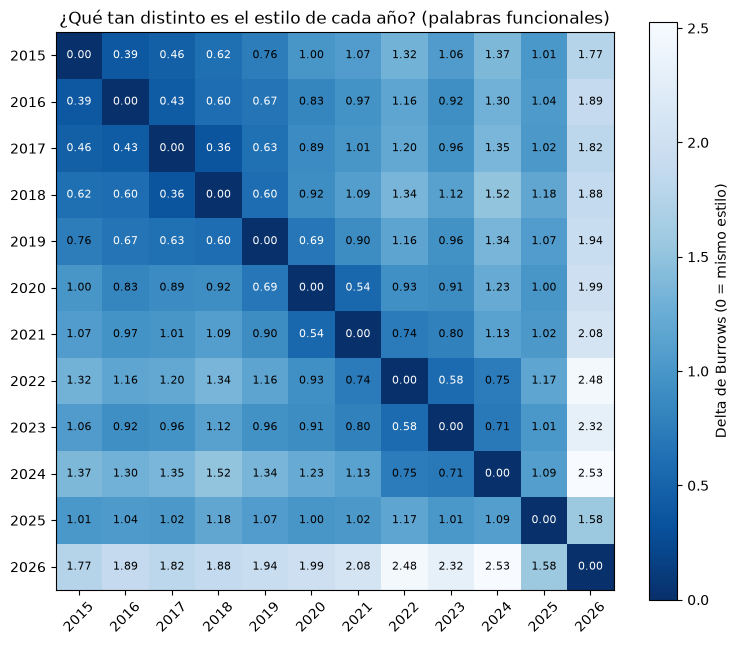

In [16]:
plt.figure(figsize=(9, 7.5))
plt.imshow(delta, cmap="Blues_r")          # invertido: más oscuro = más parecido
plt.colorbar(label="Delta de Burrows (0 = mismo estilo)")
plt.xticks(range(len(anios)), anios, rotation=45)
plt.yticks(range(len(anios)), anios)
for i in range(len(anios)):
    for j in range(len(anios)):
        valor = delta.iloc[i, j]
        plt.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color="white" if valor < 0.7 else "black")
plt.title("¿Qué tan distinto es el estilo de cada año? (palabras funcionales)")
plt.show()

¿Qué palabras pequeñas cambiaron más entre la primera y la última etapa? (diferencia de puntajes z)

In [17]:
antes = [anio for anio in anios if anio <= 2019]
nueva_etapa = [anio for anio in anios if anio >= 2025]
cambio_funcionales = (puntajes_z[nueva_etapa].mean(axis=1) - puntajes_z[antes].mean(axis=1)).sort_values()

pd.DataFrame({
    "se usan menos": cambio_funcionales.head(8).index,
    "cambio (z)": cambio_funcionales.head(8).values.round(1),
    "se usan más": cambio_funcionales.tail(8).index[::-1],
    "cambio (z) ": cambio_funcionales.tail(8).values[::-1].round(1),
})

,se usan menos,cambio (z),se usan más,cambio (z)
0,esa,-2.5,como,2.4
1,otras,-2.4,con,2.2
2,le,-2.4,una,2.1
3,los,-2.4,durante,2.1
4,ese,-2.2,quienes,2.1
5,otros,-2.0,desde,2.1
6,en,-2.0,su,2.0
7,cual,-1.9,también,1.7


## 7. ¿Cambió el equipo o cambió la línea editorial?

El estilo de un año puede cambiar porque **llegan reporteros nuevos** o porque **los mismos reporteros escriben distinto**.
Para separarlo comparamos a cada reportero **consigo mismo** a lo largo de los años (solo años con al menos 30 notas suyas).

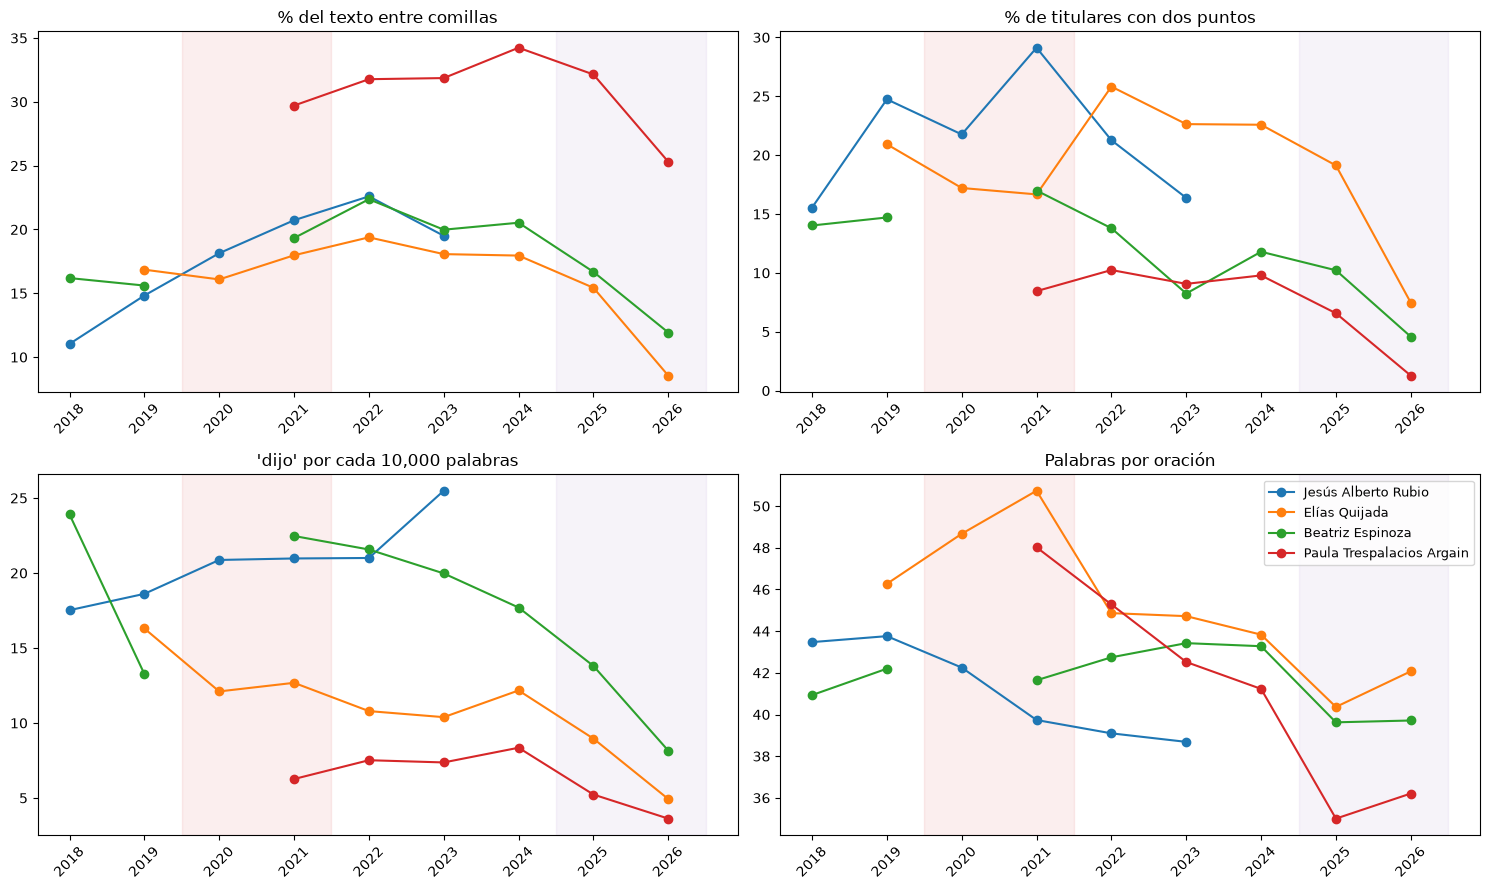

In [18]:
REPORTEROS = ["Jesús Alberto Rubio", "Elías Quijada", "Beatriz Espinoza", "Paula Trespalacios Argain"]

noticias["dijo_por_10mil"] = noticias["texto"].str.count(r"\bdijo\b") / noticias["n_palabras"] * 10000
noticias["titular_con_cita"] = (noticias["quien_habla"] != "sin cita en el titular") * 100

POR_REPORTERO = {
    "porcentaje_en_citas": "% del texto entre comillas",
    "titular_con_cita": "% de titulares con dos puntos",
    "dijo_por_10mil": "'dijo' por cada 10,000 palabras",
    "palabras_por_oracion": "Palabras por oración",
}
de_reporteros = noticias[noticias["autor"].isin(REPORTEROS)]
notas_por_reportero = pd.crosstab(de_reporteros["autor"], de_reporteros["anio"])

fig, ejes = plt.subplots(2, 2, figsize=(15, 9))
for (columna, titulo), eje in zip(POR_REPORTERO.items(), ejes.flatten()):
    promedio = de_reporteros.pivot_table(index="autor", columns="anio", values=columna, aggfunc="mean")
    promedio = promedio.where(notas_por_reportero >= 30)          # años con pocas notas no cuentan
    for reportero in REPORTEROS:
        eje.plot(promedio.columns, promedio.loc[reportero], marker="o", label=reportero)
    marcar_etapas(eje)
    eje.set_title(titulo)
    eje.set_xticks(promedio.columns)
    eje.tick_params(axis="x", rotation=45)
eje.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 7.1 ¿Cuándo cambió exactamente?

Las métricas mes por mes desde 2024. La línea vertical marca el **16 de junio de 2025**, cuando asumió la nueva rectora
(según el propio portal: *"Asume Dena María Camarena Gómez la Rectoría de la Universidad de Sonora"*).

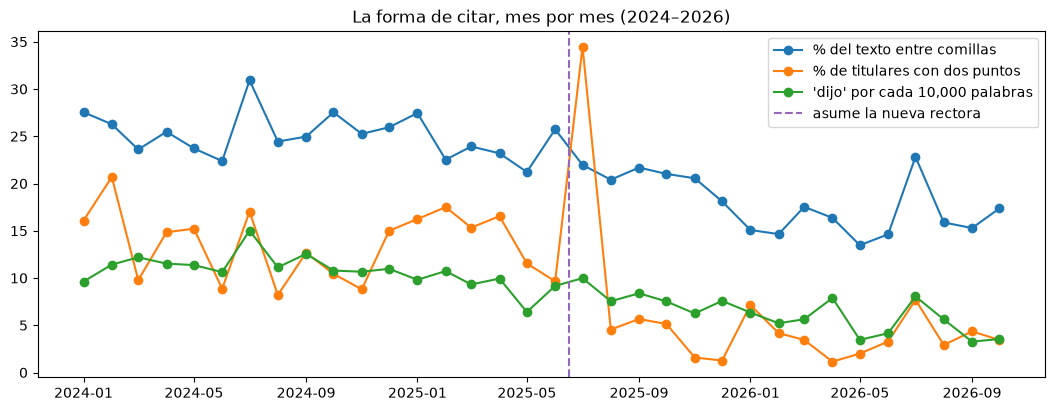

Notas por mes (julio, vacaciones, tiene muy pocas):


{Period('2025-05', 'M'): 130,
 Period('2025-06', 'M'): 114,
 Period('2025-07', 'M'): 29,
 Period('2025-08', 'M'): 66,
 Period('2025-09', 'M'): 106,
 Period('2025-10', 'M'): 156,
 Period('2025-11', 'M'): 126,
 Period('2025-12', 'M'): 79,
 Period('2026-01', 'M'): 84,
 Period('2026-02', 'M'): 120,
 Period('2026-03', 'M'): 145,
 Period('2026-04', 'M'): 87,
 Period('2026-05', 'M'): 50,
 Period('2026-06', 'M'): 61,
 Period('2026-07', 'M'): 39,
 Period('2026-08', 'M'): 103,
 Period('2026-09', 'M'): 115,
 Period('2026-10', 'M'): 145}

In [19]:
recientes = noticias[noticias["fecha"] >= "2024-01-01"]
por_mes = recientes.groupby(recientes["fecha"].dt.to_period("M").dt.to_timestamp())[
    ["porcentaje_en_citas", "titular_con_cita", "dijo_por_10mil"]
].mean()

plt.figure(figsize=(13, 4.5))
plt.plot(por_mes.index, por_mes["porcentaje_en_citas"], marker="o", label="% del texto entre comillas")
plt.plot(por_mes.index, por_mes["titular_con_cita"], marker="o", label="% de titulares con dos puntos")
plt.plot(por_mes.index, por_mes["dijo_por_10mil"], marker="o", label="'dijo' por cada 10,000 palabras")
plt.axvline(pd.Timestamp("2025-06-16"), color="tab:purple", linestyle="--", label="asume la nueva rectora")
plt.title("La forma de citar, mes por mes (2024–2026)")
plt.legend()
plt.show()

print("Notas por mes (julio, vacaciones, tiene muy pocas):")
recientes.groupby(recientes["fecha"].dt.to_period("M")).size().tail(18).to_dict()

## 8. Observaciones

### La historia en una frase

*La pandemia hizo que la Unison publicara menos noticias, pero más largas y llenas de voces. La nueva administración, desde
mediados de 2025, les quitó las voces: menos citas, titulares sin nombres y verbos que ya no solo reportan (*dijo*) sino que
realzan (*destacó*, *compartió*). Y lo hicieron los mismos reporteros: cambió la línea editorial, no el equipo.*

### La producción (sección 3)

- **Antes:** 1,700–2,400 notas al año, 6–8 por día publicado y un equipo de ~9 firmas (las tres principales escriben 61–73%).
- **Pandemia:** al 29 de octubre de 2020 había 697 notas contra 1,333 de 2019 (**−48%**); solo hubo notas en 67% de los días
  y las de fin de semana subieron de ~4% a 7%.
- **Después:** se recupera a ~1,600 notas al año, pero nunca vuelve al nivel de antes.
- **Nueva etapa:** 2026 lleva 14% menos notas que 2025 al mismo día, casi no se publica en fin de semana (0.9%) y el equipo
  es más chico y concentrado: 6 firmas, y tres reporteras y reporteros (Espinoza, Trespalacios y Quijada) escriben 78% de las notas.
- **El equipo cambia por relevos:** hasta 2017 firmaban con iniciales (*JAR*, *BE* y *LMA* escribían 60–73%); en 2019–2021, Rubio,
  Quijada y Mendívil; desde 2022 entra Trespalacios y desde 2024 el trío Espinoza–Trespalacios–Quijada.

### La forma (sección 4)

- **La pandemia alargó las notas:** de 371 palabras (2015) a **587** (2021), de 8 a 12–13 párrafos y con oraciones más largas (45 palabras).
- **Lo que se quedó:** desde 2022 las notas se acortan (~440 palabras en 2025–2026) pero los **párrafos siguen cortos**
  (de ~46 a ~40 palabras): un formato más de lectura en pantalla.
- **2025–2026:** oraciones más cortas (de ~42 a ~39 palabras).
- **Legibilidad:** el INFLESZ está entre 24 y 30 todos los años, "muy difícil" según la escala, sobre todo por las oraciones de
  ~40 palabras. En 2026 baja a 24.7 aunque las oraciones son más cortas: las **palabras son más largas** (de 5.2 a 5.5 letras en promedio).

### Las voces (sección 5)

- **Más palabras de otros:** el texto entre comillas pasa de 13–15% (antes) a **22–25%** (2022–2024), y casi 90% de las notas
  tiene alguna cita (contra 70–87% antes). En 2026 baja a 16%.
- **Titulares:** los que citan a una **persona por su nombre** llegan a 10.6% en 2021 y los de **académicos y especialistas** a
  3.5–4.9% en 2022–2024. En **2026, 96% de los titulares ya no cita a nadie**.
- **Verbos:** *dijo* cae a la mitad (de 16.8 a 8.3 por cada 10,000 palabras) mientras suben *destacó* (7.6 → 11.6), *explicó* (4.4 → 9.5),
  *compartió* (1.0 → 4.7) y *detalló* (0.9 → 4.5). Bajan *afirmó*, *sostuvo*, *apuntó* y *advirtió*.
  Parte del cambio es gradual (*explicó* y *detalló* suben desde la pandemia), pero la caída de *dijo* es de 2025–2026.

### La huella de estilo (sección 6)

- Solo con la frecuencia de 60 palabras pequeñas, los años se agrupan en **2015–2018**, **2020–2021** y **2022–2024** (Delta de 0.4–0.8
  dentro de cada grupo); 2019 queda entre las dos primeras etapas y 2025 es un año de transición.
- **2026 es el año más distinto de todos** (Delta de 1.6 a 2.5 contra cualquier otro año).
- Bajan *los, otros, otras, ese, esa, le* y suben *quienes, como, con, una, su, durante*. El aumento de *quienes* y la caída de
  *los* y *otros* coinciden con el lenguaje incluyente que vimos en el notebook 02 (*quienes estudian* en lugar de *los estudiantes*).

### ¿El equipo o la línea editorial? (sección 7)

- **Los mismos reporteros cambian.** Entre 2024 y 2026: Quijada pasa de 18% a 9% del texto entre comillas y de 23% a 8% de titulares
  con dos puntos; Espinoza, de 20% a 12% y de 12% a 5%; Trespalacios, de 34% a 25% y de 10% a 1%. Los tres usan *dijo* la mitad o menos.
- **Mes por mes**, el cambio empieza justo después del **16 de junio de 2025**, cuando asume la nueva rectora: los titulares con
  dos puntos pasan de ~15% (enero–abril de 2025) a ~5% desde agosto, y el texto entre comillas de ~25% a ~15–17% en 2026.
  Los datos muestran que coinciden en el tiempo; no prueban la causa.
- En la pandemia también cambiaron los mismos reporteros: Rubio pasa de 15% a 21% de texto entre comillas y Quijada alarga
  sus oraciones (de 46 a 51 palabras).

### Limitaciones

- Contamos oraciones por signos de puntuación y sílabas de forma aproximada: sirven para comparar años, no como valores exactos.
- Antes de 2018 las firmas son iniciales; en 2018 conviven iniciales y nombres, así que ese año el equipo parece más grande.
- Las citas se detectan por las comillas y "quién habla" en los titulares se clasifica con reglas sencillas.
- 2026 está incompleto (hasta octubre).

### Para el documento final

Las gráficas que mejor cuentan esta historia: noticias por año (3.1), forma por año (4), texto entre comillas (5.1),
cambio en los verbos (5.3), la huella de estilo (6), los reporteros consigo mismos (7) y el cambio mes por mes (7.1).